In [1]:
import os
print(os.getcwd())
print(os.path.exists("../data/raw/diabetes.csv"))
print(os.path.exists("data/raw/diabetes.csv"))

/Users/pedrohenrique/Desenvolvimento/tech-challenge-fase1/notebooks
True
False


In [2]:
import pandas as pd

df = pd.read_csv("../data/raw/diabetes.csv")
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [3]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [4]:
colunas_com_zero_invalido = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

zeros = (df[colunas_com_zero_invalido] == 0).sum()
percentual = (zeros / len(df) * 100).round(1)

print(pd.DataFrame({"zeros": zeros, "% do total": percentual}))

               zeros  % do total
Glucose            5         0.7
BloodPressure     35         4.6
SkinThickness    227        29.6
Insulin          374        48.7
BMI               11         1.4


In [5]:
df_limpo = df.copy()
df_limpo[colunas_com_zero_invalido] = df_limpo[colunas_com_zero_invalido].replace(0, float("nan"))

df_limpo.isna().sum()

Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64

In [6]:
for col in ["SkinThickness", "Insulin"]:
    print(col)
    print(df_limpo.groupby(df_limpo[col].isna())["Outcome"].agg(["mean", "count"]))
    print()

SkinThickness
                   mean  count
SkinThickness                 
False          0.332717    541
True           0.387665    227

Insulin
             mean  count
Insulin                 
False    0.329949    394
True     0.368984    374



In [7]:
print(df_limpo["Outcome"].value_counts())
print(df_limpo["Outcome"].value_counts(normalize=True).round(3))

Outcome
0    500
1    268
Name: count, dtype: int64
Outcome
0    0.651
1    0.349
Name: proportion, dtype: float64


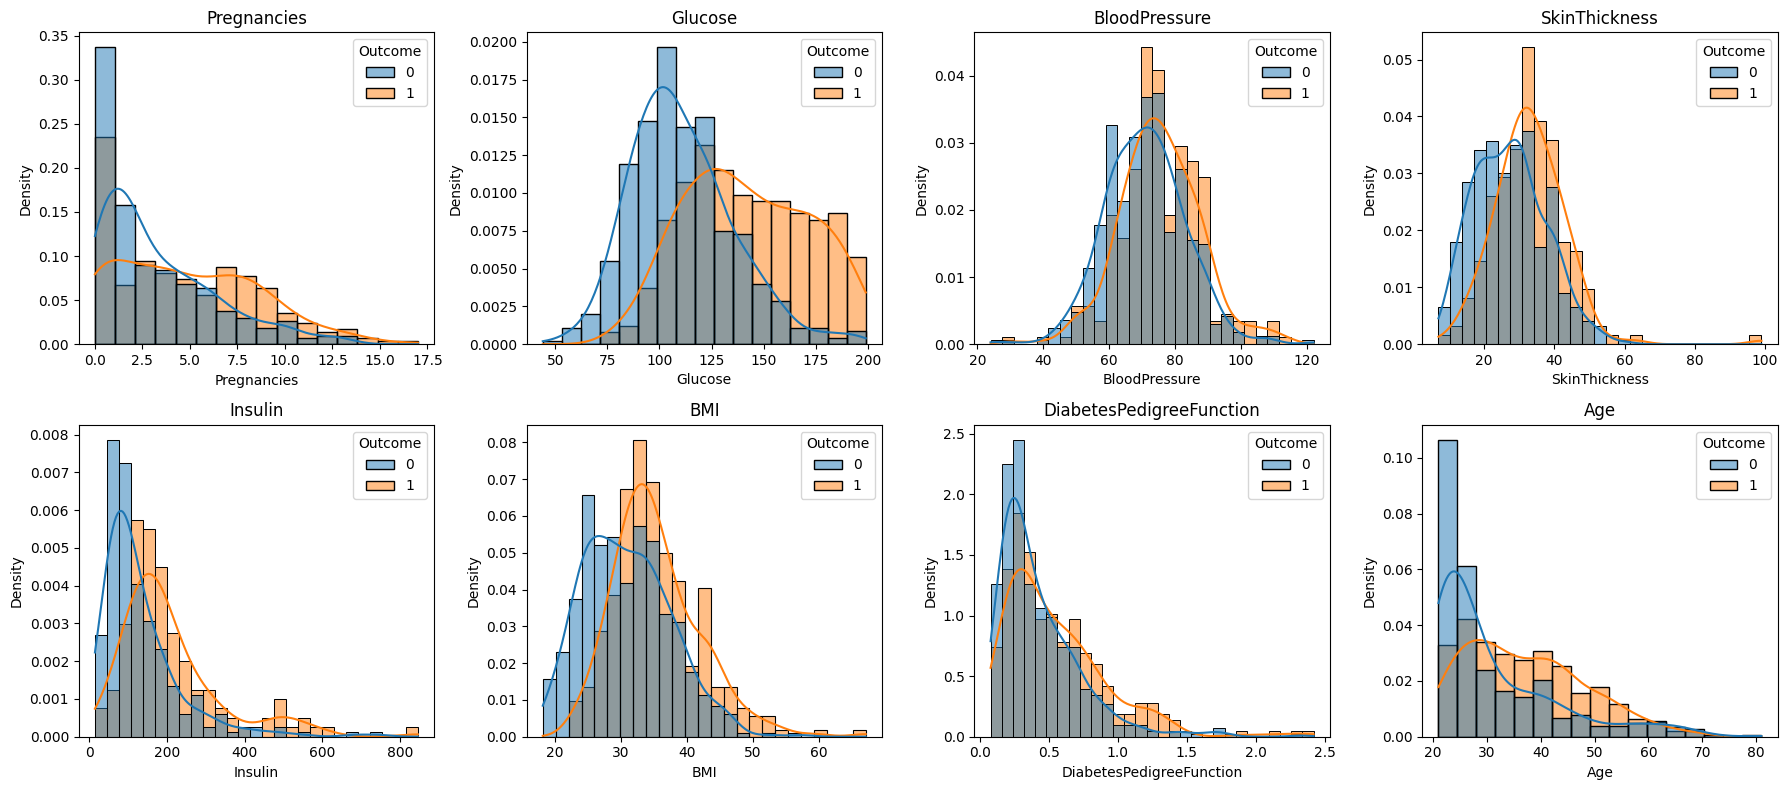

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

colunas = [c for c in df_limpo.columns if c != "Outcome"]

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), colunas):
    sns.histplot(data=df_limpo, x=col, hue="Outcome", kde=True, ax=ax, stat="density", common_norm=False)
    ax.set_title(col)
plt.tight_layout()
plt.savefig("../reports/figures/distribuicoes.png", dpi=150)
plt.show()

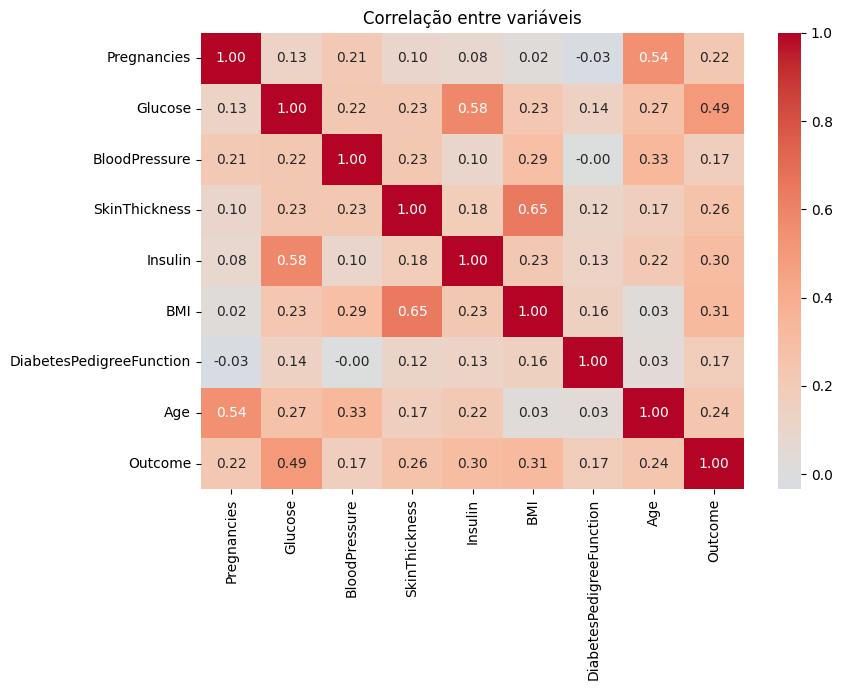

In [9]:
plt.figure(figsize=(9, 7))
sns.heatmap(df_limpo.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlação entre variáveis")
plt.tight_layout()
plt.savefig("../reports/figures/correlacao.png", dpi=150)
plt.show()

In [10]:
from sklearn.model_selection import train_test_split

X = df_limpo.drop(columns="Outcome")
y = df_limpo["Outcome"]

X_treino, X_temp, y_treino, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=42
)
X_val, X_teste, y_val, y_teste = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=42
)

for nome, parte in [("treino", y_treino), ("validação", y_val), ("teste", y_teste)]:
    print(nome, len(parte), round(parte.mean(), 3))

treino 537 0.348
validação 115 0.348
teste 116 0.353


In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

cols_com_flag = ["SkinThickness", "Insulin"]
cols_mediana = ["Pregnancies", "Glucose", "BloodPressure", "BMI",
                "DiabetesPedigreeFunction", "Age"]

preprocessador = ColumnTransformer([
    ("com_flag", Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
        ("escala", StandardScaler()),
    ]), cols_com_flag),
    ("so_mediana", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("escala", StandardScaler()),
    ]), cols_mediana),
])

modelo_lr = Pipeline([
    ("pre", preprocessador),
    ("clf", LogisticRegression(max_iter=1000, random_state=42)),
])

modelo_lr.fit(X_treino, y_treino)
print(classification_report(y_val, modelo_lr.predict(X_val)))

              precision    recall  f1-score   support

           0       0.77      0.80      0.78        75
           1       0.59      0.55      0.57        40

    accuracy                           0.71       115
   macro avg       0.68      0.68      0.68       115
weighted avg       0.71      0.71      0.71       115



/Users/pedrohenrique/Desenvolvimento/tech-challenge-fase1/.venv/lib/python3.12/site-packages/sklearn/linear_model/_linear_loss.py:165: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/pedrohenrique/Desenvolvimento/tech-challenge-fase1/.venv/lib/python3.12/site-packages/sklearn/linear_model/_linear_loss.py:165: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/pedrohenrique/Desenvolvimento/tech-challenge-fase1/.venv/lib/python3.12/site-packages/sklearn/linear_model/_linear_loss.py:165: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/pedrohenrique/Desenvolvimento/tech-challenge-fase1/.venv/lib/python3.12/site-packages/sklearn/linear_model/_linear_loss.py:295: RuntimeWarning: divide by zero encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/Users/pedrohenrique/Desenvolvimento/tech-challenge-fas

In [12]:
import numpy as np

Xt = modelo_lr.named_steps["pre"].transform(X_treino)
print("dados transformados finitos:", np.isfinite(Xt).all())
print("coeficientes finitos:", np.isfinite(modelo_lr.named_steps["clf"].coef_).all())

dados transformados finitos: True
coeficientes finitos: True


In [13]:
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

def criar_pipeline(clf):
    return Pipeline([("pre", clone(preprocessador)), ("clf", clf)])

modelos = {
    "LogReg": criar_pipeline(LogisticRegression(max_iter=1000, random_state=42)),
    "LogReg balanceada": criar_pipeline(
        LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42)),
    "RandomForest balanceada": criar_pipeline(
        RandomForestClassifier(n_estimators=300, class_weight="balanced",
                               min_samples_leaf=5, random_state=42)),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = ["recall", "precision", "f1", "roc_auc"]

for nome, modelo in modelos.items():
    r = cross_validate(modelo, X_treino, y_treino, cv=cv, scoring=scoring)
    print(nome)
    for m in scoring:
        print(f"  {m}: {r['test_' + m].mean():.3f} ± {r['test_' + m].std():.3f}")

LogReg
  recall: 0.578 ± 0.094
  precision: 0.754 ± 0.084
  f1: 0.646 ± 0.055
  roc_auc: 0.829 ± 0.031


/Users/pedrohenrique/Desenvolvimento/tech-challenge-fase1/.venv/lib/python3.12/site-packages/sklearn/linear_model/_linear_loss.py:165: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/pedrohenrique/Desenvolvimento/tech-challenge-fase1/.venv/lib/python3.12/site-packages/sklearn/linear_model/_linear_loss.py:165: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/pedrohenrique/Desenvolvimento/tech-challenge-fase1/.venv/lib/python3.12/site-packages/sklearn/linear_model/_linear_loss.py:165: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/pedrohenrique/Desenvolvimento/tech-challenge-fase1/.venv/lib/python3.12/site-packages/sklearn/linear_model/_linear_loss.py:295: RuntimeWarning: divide by zero encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/Users/pedrohenrique/Desenvolvimento/tech-challenge-fas

LogReg balanceada
  recall: 0.712 ± 0.056
  precision: 0.618 ± 0.030
  f1: 0.660 ± 0.024
  roc_auc: 0.829 ± 0.031
RandomForest balanceada
  recall: 0.690 ± 0.086
  precision: 0.641 ± 0.091
  f1: 0.661 ± 0.068
  roc_auc: 0.837 ± 0.042


/Users/pedrohenrique/Desenvolvimento/tech-challenge-fase1/.venv/lib/python3.12/site-packages/sklearn/linear_model/_linear_loss.py:165: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/pedrohenrique/Desenvolvimento/tech-challenge-fase1/.venv/lib/python3.12/site-packages/sklearn/linear_model/_linear_loss.py:165: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/pedrohenrique/Desenvolvimento/tech-challenge-fase1/.venv/lib/python3.12/site-packages/sklearn/linear_model/_linear_loss.py:165: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/pedrohenrique/Desenvolvimento/tech-challenge-fase1/.venv/lib/python3.12/site-packages/sklearn/linear_model/_linear_loss.py:295: RuntimeWarning: divide by zero encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/Users/pedrohenrique/Desenvolvimento/tech-challenge-fas

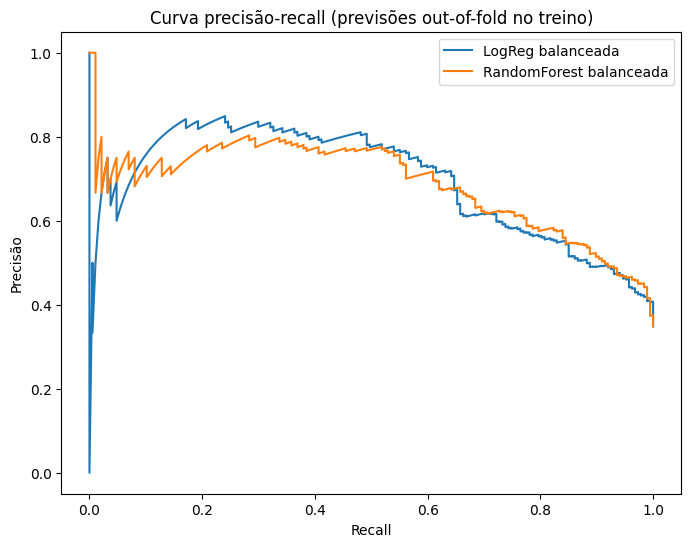

LogReg balanceada
  limiar 0.2: recall=0.95  precisão=0.46
  limiar 0.3: recall=0.88  precisão=0.51
  limiar 0.4: recall=0.80  precisão=0.56
  limiar 0.5: recall=0.71  precisão=0.62
  limiar 0.6: recall=0.64  precisão=0.71
RandomForest balanceada
  limiar 0.2: recall=0.96  precisão=0.46
  limiar 0.3: recall=0.88  precisão=0.54
  limiar 0.4: recall=0.78  precisão=0.59
  limiar 0.5: recall=0.69  precisão=0.63
  limiar 0.6: recall=0.56  precisão=0.73


In [14]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve, precision_score, recall_score
import matplotlib.pyplot as plt

nomes = ["LogReg balanceada", "RandomForest balanceada"]
proba_oof = {
    nome: cross_val_predict(modelos[nome], X_treino, y_treino, cv=cv,
                            method="predict_proba")[:, 1]
    for nome in nomes
}

fig, ax = plt.subplots(figsize=(8, 6))
for nome, p in proba_oof.items():
    prec, rec, _ = precision_recall_curve(y_treino, p)
    ax.plot(rec, prec, label=nome)
ax.set_xlabel("Recall")
ax.set_ylabel("Precisão")
ax.set_title("Curva precisão-recall (previsões out-of-fold no treino)")
ax.legend()
plt.savefig("../reports/figures/precision_recall.png", dpi=150)
plt.show()

for nome, p in proba_oof.items():
    print(nome)
    for t in [0.2, 0.3, 0.4, 0.5, 0.6]:
        pred = (p >= t).astype(int)
        print(f"  limiar {t}: recall={recall_score(y_treino, pred):.2f}  "
              f"precisão={precision_score(y_treino, pred):.2f}")

In [15]:
import numpy as np
from sklearn.metrics import confusion_matrix

RECALL_MINIMO = 0.85  # ajuste conforme a sua decisão

limiares = np.arange(0.10, 0.80, 0.01)
modelo_escolhido = "LogReg balanceada"
p_oof = proba_oof[modelo_escolhido]

aceitaveis = [t for t in limiares
              if recall_score(y_treino, (p_oof >= t).astype(int)) >= RECALL_MINIMO]
limiar = max(aceitaveis)
print("limiar escolhido:", round(limiar, 2))

modelos[modelo_escolhido].fit(X_treino, y_treino)
p_val = modelos[modelo_escolhido].predict_proba(X_val)[:, 1]
pred_val = (p_val >= limiar).astype(int)

print("recall validação:", round(recall_score(y_val, pred_val), 2))
print("precisão validação:", round(precision_score(y_val, pred_val), 2))
print(confusion_matrix(y_val, pred_val))

limiar escolhido: 0.35
recall validação: 0.92
precisão validação: 0.54
[[44 31]
 [ 3 37]]


/Users/pedrohenrique/Desenvolvimento/tech-challenge-fase1/.venv/lib/python3.12/site-packages/sklearn/linear_model/_linear_loss.py:165: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/pedrohenrique/Desenvolvimento/tech-challenge-fase1/.venv/lib/python3.12/site-packages/sklearn/linear_model/_linear_loss.py:165: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/pedrohenrique/Desenvolvimento/tech-challenge-fase1/.venv/lib/python3.12/site-packages/sklearn/linear_model/_linear_loss.py:165: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/pedrohenrique/Desenvolvimento/tech-challenge-fase1/.venv/lib/python3.12/site-packages/sklearn/linear_model/_linear_loss.py:295: RuntimeWarning: divide by zero encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/Users/pedrohenrique/Desenvolvimento/tech-challenge-fas

In [16]:
modelo_final = modelos["LogReg balanceada"]
nomes = modelo_final.named_steps["pre"].get_feature_names_out()
coefs = modelo_final.named_steps["clf"].coef_[0]

tabela = pd.DataFrame({
    "variavel": nomes,
    "coef": coefs,
    "odds_ratio": np.exp(coefs),
}).sort_values("coef", ascending=False)

print(tabela.round(2).to_string(index=False))

                                variavel  coef  odds_ratio
                     so_mediana__Glucose  1.14        3.13
                         so_mediana__BMI  0.78        2.18
                 so_mediana__Pregnancies  0.44        1.55
    so_mediana__DiabetesPedigreeFunction  0.30        1.35
      com_flag__missingindicator_Insulin  0.19        1.21
                         so_mediana__Age  0.11        1.12
                       com_flag__Insulin  0.02        1.02
com_flag__missingindicator_SkinThickness  0.00        1.01
               so_mediana__BloodPressure -0.04        0.97
                 com_flag__SkinThickness -0.11        0.90


In [17]:
def montar_preprocessador(com_flag):
    return ColumnTransformer([
        ("grupo_a", Pipeline([
            ("imputer", SimpleImputer(strategy="median", add_indicator=com_flag)),
            ("escala", StandardScaler()),
        ]), cols_com_flag),
        ("grupo_b", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("escala", StandardScaler()),
        ]), cols_mediana),
    ])

for com_flag in [True, False]:
    pipe = Pipeline([
        ("pre", montar_preprocessador(com_flag)),
        ("clf", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42)),
    ])
    r = cross_validate(pipe, X_treino, y_treino, cv=cv, scoring=["recall", "f1", "roc_auc"])
    print("com flag" if com_flag else "sem flag")
    for m in ["recall", "f1", "roc_auc"]:
        print(f"  {m}: {r['test_' + m].mean():.3f} ± {r['test_' + m].std():.3f}")

com flag
  recall: 0.712 ± 0.056
  f1: 0.660 ± 0.024
  roc_auc: 0.829 ± 0.031
sem flag
  recall: 0.717 ± 0.071
  f1: 0.669 ± 0.034
  roc_auc: 0.837 ± 0.032


/Users/pedrohenrique/Desenvolvimento/tech-challenge-fase1/.venv/lib/python3.12/site-packages/sklearn/linear_model/_linear_loss.py:165: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/pedrohenrique/Desenvolvimento/tech-challenge-fase1/.venv/lib/python3.12/site-packages/sklearn/linear_model/_linear_loss.py:165: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/pedrohenrique/Desenvolvimento/tech-challenge-fase1/.venv/lib/python3.12/site-packages/sklearn/linear_model/_linear_loss.py:165: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/pedrohenrique/Desenvolvimento/tech-challenge-fase1/.venv/lib/python3.12/site-packages/sklearn/linear_model/_linear_loss.py:295: RuntimeWarning: divide by zero encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/Users/pedrohenrique/Desenvolvimento/tech-challenge-fas

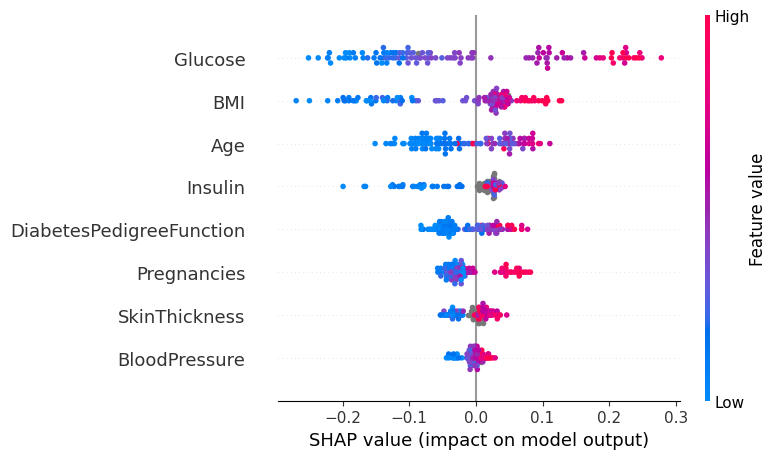

In [18]:
import shap

ordem = cols_com_flag + cols_mediana  # ordem das colunas na saída do ColumnTransformer

rf = Pipeline([
    ("pre", montar_preprocessador(False)),
    ("clf", RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                   min_samples_leaf=5, random_state=42)),
])
rf.fit(X_treino, y_treino)

X_val_t = pd.DataFrame(rf.named_steps["pre"].transform(X_val), columns=ordem)

explainer = shap.TreeExplainer(rf.named_steps["clf"])
sv = explainer(X_val_t)
if sv.values.ndim == 3:      # RF devolve uma saída por classe
    sv = sv[:, :, 1]         # fica só a classe 1 (diabetes)

# mostra os valores originais (mg/dL, kg/m², anos) no gráfico, não os padronizados
sv = shap.Explanation(values=sv.values, base_values=sv.base_values,
                      data=X_val[ordem].values, feature_names=ordem)

shap.plots.beeswarm(sv, show=False)
plt.tight_layout()
plt.savefig("../reports/figures/shap_beeswarm.png", dpi=150, bbox_inches="tight")
plt.show()

probabilidade de diabetes: 0.87 | real: 1


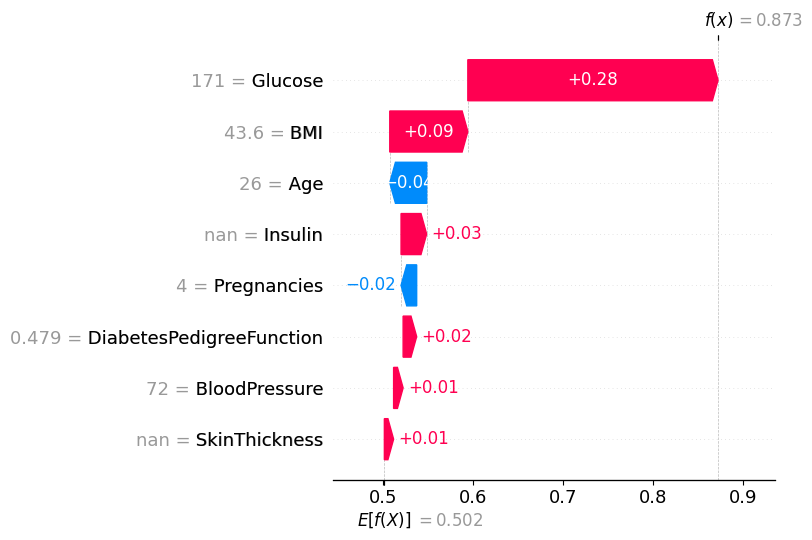

In [19]:
proba_rf = rf.predict_proba(X_val)[:, 1]
i = int(np.argmax(proba_rf >= 0.5))
print("probabilidade de diabetes:", round(proba_rf[i], 2), "| real:", y_val.iloc[i])

shap.plots.waterfall(sv[i], show=False)
plt.tight_layout()
plt.savefig("../reports/figures/shap_waterfall.png", dpi=150, bbox_inches="tight")
plt.show()